## Setup

### Imports

In [1]:
import os

import polars as pl
import numpy as np
from matplotlib import pyplot as plt, patches, rcParams
import synapseclient

rcParams["font.family"] = "Arial"
rcParams["font.size"] = 7

### Constants

In [2]:
# Jupyter server should be running from src/python
# assumes auth_token.txt exists in src/python as described in setup instructions
AUTH_TOKEN = os.path.abspath("auth_token.txt")

# cached metadata table, parquet format, on synapse 
META_CACHE_SYNID = "syn74775994"

# cached combined -omics data table, parquet format, on synapse
OMICS_CACHE_SYNID = "syn74775996"

# Jupyter server should be running from src/python
FIGURE_DIR = os.path.join(
    os.path.dirname(os.path.dirname(os.getcwd())),
    "analysis",
    "mutations",
    "_figures"
)

# key: block label
# value: color
COLORS = {
    "Transcriptomics": "#EF476F",
    "Phosphoproteomics": "#F7866B",
    "Proteomics": "#FFD166",
    "Acetylomics": "#06D6A0",
    "Lipidomics": "#11A2B2",
    "Metabolomics": "#0B6584",
    "Filtered": "#444444"
}

In [3]:
# ensure figure directory exist
os.makedirs(FIGURE_DIR, exist_ok=True)

### Synapse login

In [4]:
with open(AUTH_TOKEN, "r") as atf:
    SYN = synapseclient.login(authToken=atf.read())


UPGRADE AVAILABLE

A more recent version of the Synapse Client (4.14.0) is available. Your version (4.11.0) can be upgraded by typing:
   pip install --upgrade synapseclient

Python Synapse Client version 4.14.0 release notes

https://python-docs.synapse.org/news/


Welcome, dylan.ross!



### Load metadata and omics data from cache

In [5]:
meta = pl.read_parquet(SYN.get(META_CACHE_SYNID).path)
meta

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_56194/3955249378.py:1: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  meta = pl.read_parquet(SYN.get(META_CACHE_SYNID).path)



[syn74775994:metadata.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/metadata.parquet, skipping download.


Sample,Age,Sex,Race,Study,FLT3_ITD,NPM1
str,f64,str,str,str,bool,bool
"""11-00261""",74.0,"""Male""","""White""","""BeatAML""",true,false
"""11-00503""",54.0,"""Female""","""White""","""BeatAML""",true,true
"""11-00475""",65.0,"""Male""","""White""","""BeatAML""",true,true
"""12-00032""",70.0,"""Male""","""White""","""BeatAML""",true,false
"""11-00376""",49.0,"""Male""","""White""","""BeatAML""",true,true
…,…,…,…,…,…,…
"""16-01109-Bridge""",33.0,"""Male""","""Black""","""pilotStudy""",false,false
"""16-01191-Bridge""",65.0,"""Female""","""White""","""pilotStudy""",false,false
"""17-00025-Bridge""",39.0,"""Female""","""White""","""pilotStudy""",true,true


In [6]:
combined = pl.read_parquet(SYN.get(OMICS_CACHE_SYNID).path)
combined

[WARNING] /var/folders/nb/ykfs58f552d0d0jd_2jnkx_80000gp/T/ipykernel_56194/4040283258.py:1: DeprecationWarning: Call to deprecated method get. (To be removed in 5.0.0. Use `from synapseclient.operations import get` instead.) -- Deprecated since version 4.11.0.
  combined = pl.read_parquet(SYN.get(OMICS_CACHE_SYNID).path)



[syn74775996:combined_omics_data.parquet]: Found existing file at /Users/dylan.ross/Projects/AML_outcome_disparities/261016_diffex_overview/diffex_overview/aml_outcome_disparities/analysis/mutations/_cache/combined_omics_data.parquet, skipping download.


OmicsType,Feature,11-00261,11-00503,11-00475,12-00032,11-00376,11-00378,11-00382,11-00388,11-00416,11-00465,11-00466,12-00123,12-00127,12-00145,12-00196,12-00294,12-00383,13-00033,13-00034,13-00075,13-00077,13-00123,13-00149,13-00157,13-00160,13-00186,13-00195,13-00226,13-00262,13-00331,13-00450,13-00468,14-00495,13-00558,13-00581,…,C-95-068,C-01-1665,C-09-1033,C-99-2136,C-05-1782,94-C-376,PS88-0050,C-01-2163,C-02-0350,C-04-0434,C-01-0171,PS88-0140,C-11-2295,C-99-1077,C-05-0004,C-05-3159,C-05-4372,PS89-0158,C-01-0930,C-98-0031,94-C-077,C-98-0033,C-98-0665,C-99-1700,C-02-1356,C-99-2065,14-00528-Bridge,16-00120-Bridge,16-00494-Bridge,16-00627-Bridge,16-00731-Bridge,16-01100-Bridge,16-01109-Bridge,16-01191-Bridge,17-00025-Bridge,17-00741-Bridge,17-00881-Bridge
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Acetylomics""","""ACAA2-K234k""",-2.79,-1.32,-0.07,-0.762,-0.1896,-1.0262,-1.88,-2.1,-1.38,1.17,-1.37,0.484,-0.1312,-0.946,0.496,-0.239233,1.0506,0.669,-0.13,-0.141,0.371,-0.5858,2.2,0.564,-0.7388,0.0392,1.01,-0.326,-0.0122,0.681,-0.143617,-0.09562,2.34,-0.522,0.571,…,-0.740195,0.056017,1.525606,-0.970053,0.912385,0.415692,-0.3854,-1.527722,-0.465969,-0.417754,0.374158,-0.285991,1.689777,-0.286936,-1.355843,-1.783394,-0.108936,-1.092201,-0.704166,0.16671,-0.802912,0.24294,-1.08595,-0.37591,1.766804,-1.017518,-1.686547,-2.171659,-1.095024,-1.067707,-0.778423,-0.543555,0.740597,0.360673,0.027206,-0.568194,0.311076
"""Acetylomics""","""ACAD9-K202k""",-0.195,-0.357,-0.36,0.356,0.905,0.207,-0.834,-0.373,-0.271771,0.0433,-0.799,0.6184,-2.44,0.438,-0.0222,-0.513,0.389,-0.07794,-0.5118,-0.544,0.155,-0.136,0.23536,-0.471,-0.511,0.214,1.19,0.213786,0.694,-1.3,0.189,0.1742,2.15,1.17,0.523,…,-0.07763,0.213362,0.570992,-0.828076,1.1831,-1.511869,-0.009541,-0.487009,-1.085725,0.100794,0.674999,-0.25304,1.075163,0.364581,-0.507267,-0.1974,1.627,-0.660512,-0.644078,-0.276514,-0.622194,0.483175,1.45712,0.155145,-1.235691,-0.265326,-0.330737,-0.566252,-0.724165,0.207464,-0.395339,0.362696,0.286919,-0.602037,0.194048,-0.508715,-0.138507
"""Acetylomics""","""ACADM-K304k""",-0.129,-0.0232,0.367,-0.219,0.35,-0.7842,-0.53,0.457,-1.13,-1.24,1.59,0.114,-0.0785,-1.07,0.286,-0.296979,1.26,-0.2968,-0.313,0.366,-0.803,-1.18,1.79,0.585,-1.46,-0.663,1.05,1.96,-1.03,0.729,0.421,0.00204,1.39,-0.3006,-0.0156,…,-0.025817,0.076672,-0.310245,-1.19684,0.517396,0.369655,-0.694533,-1.153399,-2.428373,-0.117239,0.130378,-0.284755,1.54642,-0.224275,-1.205137,-1.247686,0.675267,-1.064369,-0.076896,-0.988707,-1.371136,0.38916,-1.102276,-1.272929,0.014274,-1.207984,-0.627549,-2.467522,-0.71158,-0.672011,-1.563158,-1.060444,0.034066,-0.994443,-0.024539,-0.595167,-1.370965
"""Acetylomics""","""ACADVL-K278k""",0.272,0.81,0.265,-0.858974,1.43,-0.3522,-1.486741,-1.035738,-1.03934,0.658,0.563,1.16,0.726,-1.03,1.4,-0.328,-0.582,-2.29,0.596,1.13,-0.6976,-0.225,1.37,-0.82,-1.9422,-1.46,0.175,0.0792,0.507,0.52,-0.926,-1.281372,-0.152,-1.925,-1.26,…,-0.416003,-0.432192,1.182928,-1.049746,-1.909679,-0.075547,-0.960016,-0.708188,-1.025387,-0.443936,1.004101,-0.314048,1.280458,0.231344,-0.711069,-0.104481,-0.064754,-1.169472,0.946654,-1.107658,-0.412209,1.016264,-2.307984,-0.028166,0.831407,-2.584908,0.002312,-1.849316,-0.621441,-2.109005,-1.389221,-0.992909,0.247213,-1.049815,0.351727,-0.419173,-1.870117
"""Acetylomics""","""ACADVL-K298k""",-0.622,0.421,-0.478,-2.19,1.26,-0.4816,-0.718974,2.19,-0.656,0.235,0.0553,0.699,-0.605,0.465,0.915,-0.679073,1.16,-0.1993,-0.1073,0.149,0.188,0.265,0.865,-0.456,0.31,-0.647,1.38,0.533708,-0.979,0.174907,-1.5600e-25,0.2114,0.974,-0.542,-1.03,…,-1.109983,-0.410377,0.883659,-0.129818,-0.651763,0.020461,0.199043,-0.233644,-0.517838,-0.023063,0.561925,0.312539,0.861988,0.109789,-0.905637,0.285302,-0.1258

In [7]:
# report on the number of features in each block
combined.group_by("OmicsType").len().sort("len", descending=True)

OmicsType,len
str,u32
"""Transcriptomics""",17878
"""Proteomics""",7966
"""Phosphoproteomics""",7200
"""Acetylomics""",638
"""Lipidomics""",343
"""Metabolomics""",49


## Summarize coverage of omics data by mutation state and population

In [8]:
def _count_samples_with_block_and_total(
    race,
    mut,
    ot,
):
    # filter metadata by race 
    _meta = meta.filter(pl.col("Race") == race)
    # filter metadata by mutations
    match mut:
        case "NPM1-/FLT3-ITD-":
            _meta = _meta.filter(
                ~pl.col("NPM1")
                & ~pl.col("FLT3_ITD")
            )
        case "NPM1+/FLT3-ITD-":
            _meta = _meta.filter(
                pl.col("NPM1")
                & ~pl.col("FLT3_ITD")
            )
        case "NPM1-/FLT3-ITD+": 
            _meta = _meta.filter(
                ~pl.col("NPM1")
                & pl.col("FLT3_ITD")
            )
        case "NPM1+/FLT3-ITD+": 
            _meta = _meta.filter(
                pl.col("NPM1")
                & pl.col("FLT3_ITD")
            )
        case _:
            assert False
    samples = _meta["Sample"].to_list()
    # count the number of samples that have the specified block
    # criterion for "having the block" is not all values are null
    # in that column
    _combined = (
        combined
        .filter(pl.col("OmicsType") == ot)
        .select(samples)
    )
    all_rows = len(_combined)
    has_block = len(
        _combined
        .null_count()
        .select(
            pl.all().eq(all_rows)
        )
        .transpose()
        .filter(~pl.col("column_0"))
    )
    return has_block, len(samples)


# key: (race label, mutation label, omics_type)
# value: (sample count with omics_type, sample count with or without omics_type)
omics_counts = {
    (race == "Black", mut, odt): _count_samples_with_block_and_total(race, mut, odt)
    for race in ["White", "Black"]
    for mut in [
        "NPM1-/FLT3-ITD-",
        "NPM1+/FLT3-ITD-",
        "NPM1-/FLT3-ITD+",
        "NPM1+/FLT3-ITD+",
    ]
    for odt in [
        "Transcriptomics", 
        "Proteomics", 
        "Phosphoproteomics", 
        "Acetylomics", 
        "Lipidomics", 
        "Metabolomics"
    ]
}

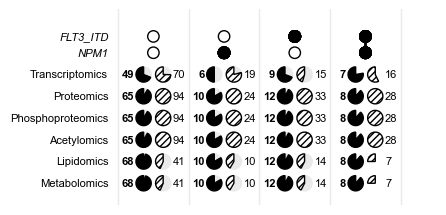

In [9]:
# --- setup ---

# figure and subpanels
fig, ax = plt.subplots(
    figsize=(4.5, 2.5),
)

# max font size 
rcParams["font.size"] = 8

# colors
c_white = "w"
c_black = "k"
c_border = c_black
c_grey = "#E9E9E9"

# misc parameters
w = 0.35            # bar width
lw = 1.             # line width for borders
r = 0.35           # circle radius
hatch = "/////"      # hatching for white bars
xfactor = 3.25
xoff = 0.45


y_flt3itd = 7.75
y_npm1 = 7

# --- helper: make a pie ---

def _add_pie(x, y, has_block, total, black=True):
    fc = c_black if black else c_white
    ec = c_border
    if has_block < 5: 
        ec = "#F00"
        if black: 
            fc = "#F00"

    theta_0 = 90
    proportion = has_block / total
    ax.add_patch(patches.Wedge(
        center=(x, y),
        r=r,
        theta1=theta_0,
        theta2=360 * proportion + theta_0,
        facecolor=fc,
        edgecolor=ec,
        hatch=None if black else hatch
    ))
    ax.text(
        x - xoff if black else x + xoff,
        y,
        str(has_block),
        ha="right" if black else "left",
        va="center",
        color=ec,
        fontweight="bold" if black else "normal"
    )


# --- plot the data ---


# draw dividing lines
for x in np.arange(0, 9 * xfactor, xfactor):
    ax.axvline(
        x + xfactor / 2,
        lw=lw,
        c=c_grey
    )

# plot the field of empty circles
for x in np.arange(xfactor, 4 * xfactor, xfactor):
    for y in range(1, 7):
        for _x in [x - xoff, x + xoff]:
            ax.add_patch(patches.Circle(
                xy=(
                    _x, 
                    y
                ),
                radius=r,
                edgecolor=c_grey,
                lw=lw,
                facecolor=c_grey
            ))

# add the mutation indicator circles

# plot the field of empty circles
for x in np.arange(xfactor, 4 * xfactor, xfactor):
    for y in [y_flt3itd, y_npm1]:
        ax.add_patch(patches.Circle(
            xy=(
                x, 
                y
            ),
            radius=r * 0.75,
            edgecolor=c_border,
            lw=lw,
            facecolor=c_white
        ))


# add block labels
block_to_y = {
    "Transcriptomics": 6,
    "Proteomics": 5,
    "Phosphoproteomics": 4,
    "Acetylomics": 3,
    "Lipidomics": 2,
    "Metabolomics": 1,
}
for blk, y in block_to_y.items():
    ax.text(
        xfactor / 2 - xoff,
        y,
        blk,
        ha="right",
        va="center"
    )

# add pies and mutation indicator circles
mut_to_x = {
    "NPM1-/FLT3-ITD-":     xfactor,
    "NPM1+/FLT3-ITD-": 2 * xfactor,
    "NPM1-/FLT3-ITD+": 3 * xfactor,
    "NPM1+/FLT3-ITD+": 4 * xfactor,
}
mut_to_ys = {
    "NPM1-/FLT3-ITD-": [],
    "NPM1-/FLT3-ITD+": [y_flt3itd],
    "NPM1+/FLT3-ITD-": [y_npm1],
    "NPM1+/FLT3-ITD+": [y_npm1, y_flt3itd],
}
mut_to_line_y1y2 = {
    "NPM1+/FLT3-ITD+": (y_npm1, y_flt3itd),
}
for (black, mut, block), (has_block, total) in omics_counts.items():
    x = mut_to_x[mut]
    if has_block > 0:
        _add_pie(
            x - xoff if black else x + xoff,
            block_to_y[block],
            has_block,
            total, 
            black=black
        )
    if (y1y2 := mut_to_line_y1y2.get(mut)) is not None:
        ax.plot(
            [x, x],
            [y1y2[0], y1y2[1]],
            "k-",
            lw=lw,
            zorder=-2
        )
    for y in mut_to_ys[mut]:
        ax.add_patch(patches.Circle(
            xy=(
                x, 
                y
            ),
            radius=r * 0.75,
            edgecolor=c_border,
            lw=lw,
            facecolor=c_black
        ))

# label the mutation circles
ax.text(
    xfactor / 2 - xoff,
    y_npm1,
    "NPM1",
    ha="right",
    va="center",
    fontstyle="italic"
)
ax.text(
    xfactor / 2 - xoff,
    y_flt3itd,
    "FLT3_ITD",
    ha="right",
    va="center",
    fontstyle="italic"
)

# --- customization ---

ax.set_xlim((0, 5 * xfactor))
ax.set_ylim((0, 9))
ax.set_aspect("equal")
ax.set_axis_off()


# --- finish ---
plt.tight_layout()
plt.savefig(
    os.path.join(FIGURE_DIR, "mutations_omics_coverage_sample_counts.png"),
    dpi=400,
    bbox_inches="tight",
    transparent=True
)
plt.show()
plt.close()